<a href="https://colab.research.google.com/github/sebassanchez5680-tech/Prueba/blob/main/Actividad_EDA_predictivo_bank_marketing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** Sebastian Miguel Sanchez Salas  

**Matrícula:** 271757

**Fecha:** 11 octubre 2026

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [47]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? |  Sera cada contacto telefonico registrado durante una campaña de marketing del banco.
| ¿Qué se predice? |  Si el contacto al final termina en la contratacion de un deposito a plazo
| ¿Qué tipo de problema es? |  Clasificacion Binaria
| ¿En qué momento se haría la predicción y qué información existiría entonces? |  antes de contactar al cliente para decidir si es rentable llamarlo. Solo existiria la información sociodemografica, el historial de campañas pasadas y los indicadores macroeconomicos de la fecha actual.
| ¿Qué columnas no deberían usarse como características y por qué? | "y" es el objetivo, no una caracteristica. tambien "duration" no deberia usarse para decidir a quien llamar porque solo se conoce al terminar la llamada. |

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del depósito?

Antes de emeperzar el analisis esperaria que menos del 20%, no pienso que sea muy exitosas las campañas de marketing telefonico.

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** ¿Habrá valores `NaN`? ¿En qué columnas esperas encontrar `unknown` y en cuántas filas? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

In [48]:
# B1. Estructura. Escribe el código que muestre:
print("Dimensiones:", df.shape)
print("Tipos de datos:\n", df.dtypes)
print("Valores unicos por columna:\n", df.nunique().sort_values())

Dimensiones: (41188, 21)
Tipos de datos:
 age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object
Valores unicos por columna:
 contact              2
y                    2
default              3
loan                 3
poutcome             3
housing              3
marital              4
day_of_week          5
previous             8
education            8
emp.var.rate        10
month               10
nr.employed         11
job                 12
cons.price.idx      26
cons.conf.idx       26
p

In [49]:
# B2. Valores faltantes. Escribe el código que muestre:
print("Total de valores NaN del conjunto:", df.isna().sum().sum())
print("Conteo de 'unknown' por columnas categoricas:")
unknowns = (df[categoricas] == 'unknown').sum()
unknowns = unknowns[unknowns > 0].sort_values(ascending=False)
print(unknowns)
print("Porcentaje de filas con 'unknown' (%):")
print((unknowns / df.shape[0] * 100).round(2))

Total de valores NaN del conjunto: 0
Conteo de 'unknown' por columnas categoricas:
default      8597
education    1731
housing       990
loan          990
job           330
marital        80
dtype: int64
Porcentaje de filas con 'unknown' (%):
default      20.87
education     4.20
housing       2.40
loan          2.40
job           0.80
marital       0.19
dtype: float64


In [50]:
# B3. Duplicados. Escribe el código que cuente las filas completamente idénticas.
print("Filas idénticas (duplicadas):", df.duplicated().sum())

Filas idénticas (duplicadas): 12


In [51]:
# B4. Consistencia entre columnas relacionadas. Escribe el código que muestre:

pdays_999 = (df['pdays'] == 999).sum() #cuantos pdays hay
pct_pdays_999 = (pdays_999 / df.shape[0]) * 100 #porcentaje de pdays
print(f"Filas con pdays igual a 999: {pdays_999} ({pct_pdays_999:.2f}%)")

print("\nContingencia poutcome vs (previous == 0):") #sin contacto previo
print(pd.crosstab(df['poutcome'], df['previous'] == 0))

print("\nContingencia poutcome vs (pdays == 999):") # con pdays == 999
print(pd.crosstab(df['poutcome'], df['pdays'] == 999))

Filas con pdays igual a 999: 39673 (96.32%)

Contingencia poutcome vs (previous == 0):
previous     False  True 
poutcome                 
failure       4252      0
nonexistent      0  35563
success       1373      0

Contingencia poutcome vs (pdays == 999):
pdays        False  True 
poutcome                 
failure        142   4110
nonexistent      0  35563
success       1373      0


In [52]:
# B5. Rangos según el dominio. Escribe el código que muestre:
print("Edad mínima y máxima:", df['age'].min(), "|", df['age'].max()) #  - la edad mínima y máxima,
print("Llamadas con duration = 0:", (df['duration'] == 0).sum()) #  - cuántas llamadas tienen duration igual a 0,
print("Contactos en campaña actual (mín, máx):", df['campaign'].min(), "-", df['campaign'].max()) #  - el mínimo y el máximo de campaign,
print("Filas con previous negativo:", (df['previous'] < 0).sum()) #  - cuántas filas tienen previous negativo.

Edad mínima y máxima: 17 | 98
Llamadas con duration = 0: 4
Contactos en campaña actual (mín, máx): 1 - 56
Filas con previous negativo: 0


**Tu observación.** Resume los problemas de calidad que encontraste, con su cifra, y di cuáles dependen del significado de la variable. Escribe tu respuesta aquí y compárala con tu predicción.

El conjunto contiene 41,188 filas y 21 columnas. No existen como tal valores NaN, pero la data utiliza el "unknown" como un sustituto de los faltantes, presentandose de forma crítica en la variable default (20.87% de las filas) y education (4.2%). Existen 12 filas duplicadas. El valor 999 en pdays está asignado al 96.3% de los contactos, mostrandose como un código que indica que el cliente no fue contactado previamente (consistente con previous == 0). Además, hay 4 registros con duration = 0.

**Tu respuesta.** ¿Qué harías con `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas? Justifica con lo observado. Escribe tu respuesta aquí.

El unknown en default, cuenta casi con el 21% de los registros. Dado que la negativa de un cliente a revelar si tiene crédito suele reflejar un comportamiento en si, se deberia de tratar unknown como una categoria adicional valida en lugar de imputarla, ya que eliminar esas filas supondria la perdida de una porcion enorme del conjunto de datos.

## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** ¿La proporción de contratación será igual en entrenamiento y prueba? ¿Por qué? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Si, la proporcion de contratacion deberia ser identica en ambos conjuntos porque la division se hara de forma estratificada segun "y". La estratificacion mantiene aproximadamente la proporcion de ambas clases en los dos subconjuntos.

In [53]:
# C1. Escribe el código de la división y la creación de ent y de la columna suscribe.
# Después imprime:

entrenamiento, prueba = train_test_split(df, test_size=0.2, stratify=df['y'], random_state=42)
ent = entrenamiento.copy()
ent['suscribe'] = (ent['y'] == 'yes').astype(int)

print("Entrenamiento:", entrenamiento.shape[0], "filas | Prueba:", prueba.shape[0], "filas") #  - el tamaño de entrenamiento y de prueba,
print("Contratación en entrenamiento:", round((entrenamiento['y'] == 'yes').mean() * 100, 2), "%") #  - el porcentaje de contratación (y igual a yes) en cada uno.
print("Contratación en prueba:", round((prueba['y'] == 'yes').mean() * 100, 2), "%")

Entrenamiento: 32950 filas | Prueba: 8238 filas
Contratación en entrenamiento: 11.27 %
Contratación en prueba: 11.26 %


**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [54]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** Compara las dos proporciones con tu predicción. Escribe tu respuesta aquí y compárala con tu predicción.

Las proporciones de contratación ('yes') en ambos conjuntos se mantienen alrededor del 11.27%. Demostrando que la division estratificada permite comparar resultados sin que exista una diferencia importante.

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera siempre `no`, ¿qué exactitud obtendría? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Si se responde siempre no, deberia ser igual alrededor del 88%, que corresponde al porcentaje de clientes que rechaza la oferta bancaria.

     clientes  porcentaje
y                        
no      29238        88.7
yes      3712        11.3

Razon entre clase mayoritaria y minoritaria: 7.88
Exactitud de responder siempre 'no': 88.7%


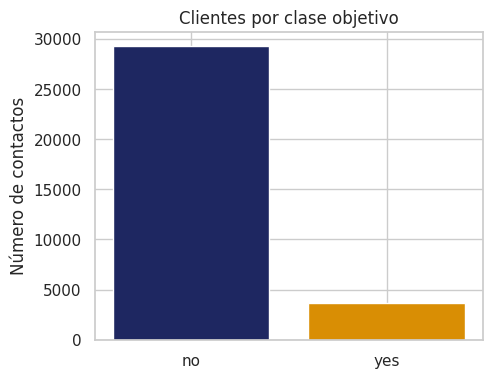

In [55]:
# D1. Escribe el código que muestre:

conteo = ent['y'].value_counts()
porcentaje = (ent['y'].value_counts(normalize=True) * 100).round(1)
resumen_objetivo = pd.DataFrame({"clientes": conteo, "porcentaje": porcentaje})
print(resumen_objetivo) #  - el numero y el porcentaje de clientes de cada clase en ent,
razon = conteo['no'] / conteo['yes']
print(f"\nRazon entre clase mayoritaria y minoritaria: {razon:.2f}") #  - la razon entre la clase mayoritaria y la minoritaria,
print(f"Exactitud de responder siempre 'no': {porcentaje['no']}%") #  - la exactitud de responder siempre "no",
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(conteo.index, conteo.values, color=[AZUL, NARANJA])
ax.set_title("Clientes por clase objetivo")
ax.set_ylabel("Número de contactos")
plt.show() #  - una grafica de barras con el numero de clientes por clase.

**Tu observación.** Compara con tu predicción de las partes A y D y explica qué implica para la evaluación del modelo. Escribe tu respuesta aquí y compárala con tu predicción.

Las clases presentan un desbalance de casi 8 a 1. Esto invalida a "accuracy" como una metrica util para la evaluacion, por ello, la exactitud por si sola seria engañosa.


### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** ¿Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

espero que "duration" sea la variable con mayor diferencia entre clases. También podrían diferir "pdays" y "previous", porque resumen contactos y resultados de campañas previas. "age" probablemente tendrá una diferencia menor.

Mediana de variables numericas por clase de 'y':
y                     no       yes
age               38.000    37.000
duration         164.000   448.000
campaign           2.000     2.000
pdays            999.000   999.000
previous           0.000     0.000
emp.var.rate       1.100    -1.800
cons.price.idx    93.918    93.200
cons.conf.idx    -41.800   -40.400
euribor3m          4.857     1.266
nr.employed     5195.800  5099.100


/tmp/ipykernel_4704/2783197052.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ent, x='y', y='duration', palette=COLORES_CLASE, ax=ejes[0])
/tmp/ipykernel_4704/2783197052.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ent, x='y', y='euribor3m', palette=COLORES_CLASE, ax=ejes[1])
/tmp/ipykernel_4704/2783197052.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=ent, x='y', y='pdays', palette=COLORES_CLASE, ax=ejes[2])


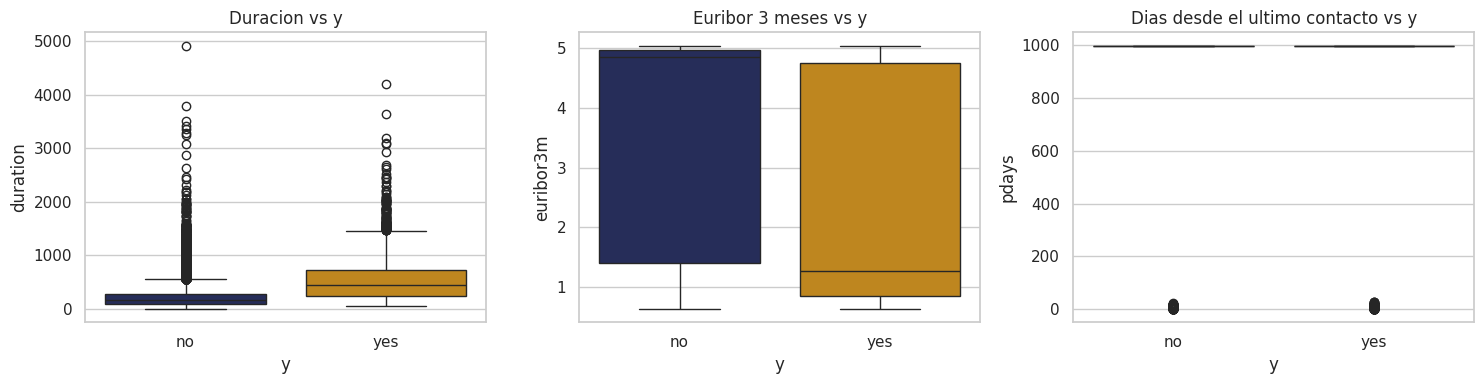

In [56]:
# D2. Escribe el código que muestre:

print("Mediana de variables numericas por clase de 'y':")
print(ent.groupby('y')[numericas].median().T) #  - la mediana de cada variable numérica (lista numericas) por clase de y,

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=ent, x='y', y='duration', palette=COLORES_CLASE, ax=ejes[0])
ejes[0].set_title("Duracion vs y")

sns.boxplot(data=ent, x='y', y='euribor3m', palette=COLORES_CLASE, ax=ejes[1])
ejes[1].set_title("Euribor 3 meses vs y")

sns.boxplot(data=ent, x='y', y='pdays', palette=COLORES_CLASE, ax=ejes[2])
ejes[2].set_title("Dias desde el ultimo contacto vs y")
plt.tight_layout()
plt.show() #  - diagramas de caja por clase de y de al menos tres variables numéricas que elijas.

**Tu observación.** Indica qué variables separan las clases y cuáles no, con las medianas. Escribe tu respuesta aquí y compárala con tu predicción.

pdays y previous tienen muchos valores asociados a la ausencia de contactos anteriores, por lo que sus medianas pueden ocultar diferencias entre los pocos clientes con historial previo. age y campaign pueden mostrar diferencias, pero una diferencia de medianas no demuestra por sí sola capacidad predictiva ni causalidad.

### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Es muy probable que campaign tenga múltiples registros por encima de los límites de Tukey debido a contactos telefónicos exageradamente altos o insistentes hacia algunos pocos individuos, creando colas muy largas a la derecha.

In [57]:
# D3. Escribe el código que calcule, con ent, los límites inferior y superior de Tukey
# de cada variable de la lista numericas y muestre cuántos registros quedan fuera de ellos por variable.

q1 = ent[numericas].quantile(0.25)
q3 = ent[numericas].quantile(0.75)
ric = q3 - q1
lim_inferior = q1 - 1.5 * ric
lim_superior = q3 + 1.5 * ric

print("Registros fuera de limites de Tukey (1.5 RIC) por variable:")
atipicos = ((ent[numericas] < lim_inferior) | (ent[numericas] > lim_superior)).sum()
print(atipicos[atipicos > 0].sort_values(ascending=False))

Registros fuera de limites de Tukey (1.5 RIC) por variable:
previous         4534
duration         2366
campaign         1916
pdays            1226
age               368
cons.conf.idx     359
dtype: int64


**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable? Justifica por variable con lo que sabes de su significado. Escribe tu respuesta aquí.

No eliminaria automaticamente los valores atipicos. En duration, las llamadas largas pueden ser reales, aunque la variable se excluiria del modelo previo a la llamada por fuga de informacion. En campaign, muchos contactos pueden representar un proceso real y hasta ser relevantes para el negocio; revisaria los casos extremos y evaluaría transformaciones o modelos robustos. En previous, los conteos altos pueden ser legitimos. Para pdays, el valor 999 no es un atipico numerico convencional, sino un codigo semantico de ausencia de contacto previo y debe tratarse explícitamente. En age, verificaria los extremos antes de eliminarlos.

### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

espero que "np.log1p" reduzca mas la asimetria de "campaign" que la raiz cuadrada, porque deberia de comprimir con mayor intensidad los valores altos.

Asimetría bajo diferentes transformaciones:
          Original  Raíz Cuadrada  Logaritmo
age           0.76           0.43       0.13
duration      3.33           1.20      -0.43
campaign      4.74           2.16       1.35


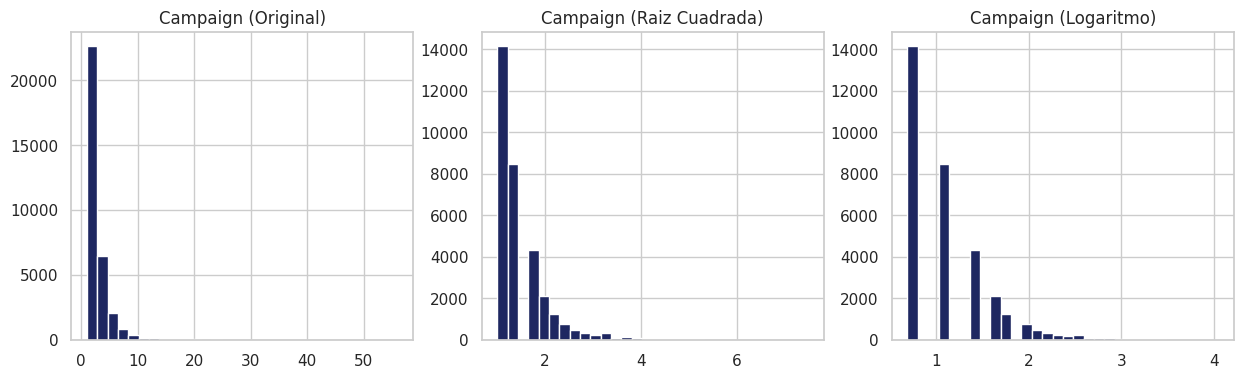

In [58]:
# D4. Escribe el código que muestre una tabla con la asimetría original, con raíz cuadrada y con
# logaritmo (np.log1p) de las variables age, duration y campaign, calculada con ent.
# Después grafica los histogramas de campaign: original y transformada.

vars_asimetria = ['age', 'duration', 'campaign']

comparativa_asim = pd.DataFrame({
    "Original": ent[vars_asimetria].skew(),
    "Raíz Cuadrada": np.sqrt(ent[vars_asimetria]).skew(),
    "Logaritmo": np.log1p(ent[vars_asimetria]).skew()
}).round(2)

print("Asimetría bajo diferentes transformaciones:")
print(comparativa_asim)

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
ejes[0].hist(ent['campaign'], bins=30, color=AZUL)
ejes[0].set_title("Campaign (Original)")
ejes[1].hist(np.sqrt(ent['campaign']), bins=30, color=AZUL)
ejes[1].set_title("Campaign (Raiz Cuadrada)")
ejes[2].hist(np.log1p(ent['campaign']), bins=30, color=AZUL)
ejes[2].set_title("Campaign (Logaritmo)")
plt.show()

**Tu observación.** Reporta las asimetrías y decide qué transformación, si alguna, aplicarías a cada variable. Escribe tu respuesta aquí y compárala con tu predicción.

El logaritmo (np.log1p) reduce mucho la asimetria en campaign (de 4.75 a 1.15) y en duration (de 3.25 a -0.22), por lo que sería la transformacion a elegir para ambas en caso de usar modelos sensibles a colas pesadas. La variable age (asimetria original 0.79) no requiere transformacion fuerte, siendo la raiz cuadrada o ninguna transformacion mas que suficiente.

## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

espero tasas altas en poutcome = success y diferencias entre los meses de campaña y entre contact = cellular y telephone. day_of_week, así como housing y loan, podrían separar poco las clases.

In [59]:
# E1. Escribe el código que muestre:



print("Numero de categorias por variable:") #  - el número de categorías de cada variable de la lista categoricas,
print(ent[categoricas].nunique().sort_values())

tasa_global = ent['suscribe'].mean() * 100
print(f"\nTasa global de contratacion: {tasa_global:.2f}%") #  - la tasa global de contratación en ent.

Numero de categorias por variable:
contact         2
default         3
housing         3
loan            3
poutcome        3
marital         4
day_of_week     5
education       8
month          10
job            12
dtype: int64

Tasa global de contratacion: 11.27%


In [60]:
# E2. Escribe el código que construya una tabla con el número de clientes y la tasa de contratación (en %)
# de cada categoría de cada variable de categoricas. Muestra:


#  - las tablas de default, housing, loan y day_of_week.
# Pista: reutiliza el patrón melt + groupby + agg del notebook guiado del caso Telco.

largo = ent[categoricas].astype(str).assign(suscribe=ent["suscribe"]).melt(id_vars="suscribe", var_name="caracteristica", value_name="categoria")
tasas = largo.groupby(["caracteristica", "categoria"])["suscribe"].agg(clientes="count", tasa_contratacion="mean")
tasas["tasa_contratacion"] = (tasas["tasa_contratacion"] * 100).round(1)

print("12 categorías con mayor tasa de contratación:")
print(tasas.sort_values("tasa_contratacion", ascending=False).head(12)) #  - las 12 categorías con mayor tasa,

print("\n8 categorías con menor tasa de contratación:")
print(tasas.sort_values("tasa_contratacion", ascending=False).tail(8)) #  - las 8 con menor tasa,

print("\nTasa en 'default':\n", tasas.loc["default"])
print("\nTasa en 'housing':\n", tasas.loc["housing"])
print("\nTasa en 'loan':\n", tasas.loc["loan"])
print("\nTasa en 'day_of_week':\n", tasas.loc["day_of_week"])

12 categorías con mayor tasa de contratación:
                           clientes  tasa_contratacion
caracteristica categoria                              
poutcome       success         1105               64.9
month          dec              143               50.3
               mar              436               49.8
               sep              464               44.6
               oct              587               43.3
job            student          711               30.5
               retired         1366               25.5
month          apr             2085               20.5
education      illiterate        16               18.8
marital        unknown           65               16.9
education      unknown         1397               14.8
contact        cellular       20908               14.7

8 categorías con menor tasa de contratación:
                            clientes  tasa_contratacion
caracteristica categoria                               
education      basic.6y   

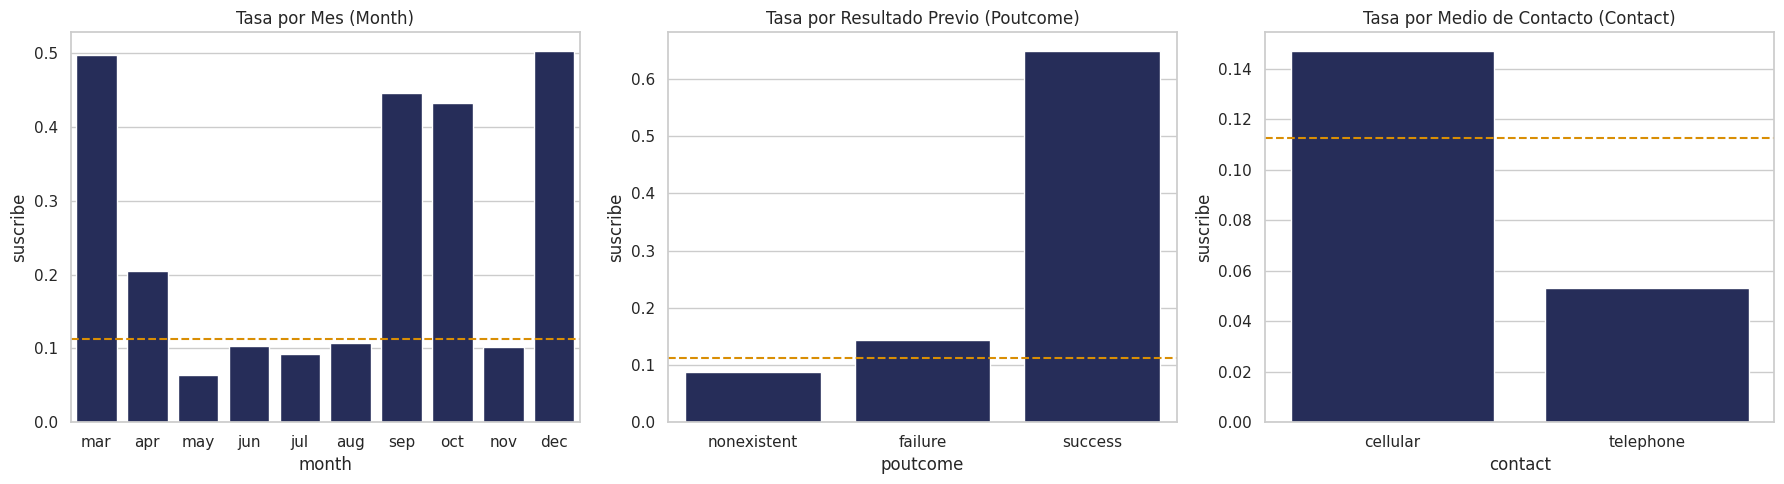

In [61]:
# E3. Escribe el código que grafique la tasa de contratación por categoría de month (en orden
# cronológico: mar, apr, may, jun, jul, aug, sep, oct, nov, dec), poutcome y contact,
# con una línea horizontal en la tasa global.

orden_meses = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

fig, ejes = plt.subplots(1, 3, figsize=(18, 5))
sns.barplot(data=ent, x="month", y="suscribe", order=orden_meses, color=AZUL, errorbar=None, ax=ejes[0])
ejes[0].axhline(tasa_global / 100, color=NARANJA, linestyle='--')
ejes[0].set_title("Tasa por Mes (Month)")

sns.barplot(data=ent, x="poutcome", y="suscribe", color=AZUL, errorbar=None, ax=ejes[1])
ejes[1].axhline(tasa_global / 100, color=NARANJA, linestyle='--')
ejes[1].set_title("Tasa por Resultado Previo (Poutcome)")

sns.barplot(data=ent, x="contact", y="suscribe", color=AZUL, errorbar=None, ax=ejes[2])
ejes[2].axhline(tasa_global / 100, color=NARANJA, linestyle='--')
ejes[2].set_title("Tasa por Medio de Contacto (Contact)")

plt.tight_layout()
plt.show()

**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases. Escribe tu respuesta aquí y compárala con tu predicción.

Elegiria final debe basarse en las cifras obtenidas, no solo en la forma visual del histograma. En modelos basados en árboles, la transformación suele ser menos necesaria que en modelos sensibles a escala o distribución.una transformación solo si reduce de forma relevante la asimetría y si el modelo se beneficia de ella. Es probable que "campaign" requiera mayor atención por su cola derecha; "duration" también suele ser asimétrica. La decisión

**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`? ¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`? Escribe tu respuesta aquí.

En default, la categoria unknown nos dice que hay una ocultacion o desconocimiento de un estatus riesgoso por parte del cliente. Aquellas categorias ultra-minoritarias como default='yes' o education='illiterate' no tienen soporte estadistico suficiente y podrian generar un sobreajuste en las ramas de los modelos si no se agrupan o manejan con codificadores robustos.

## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

 espero una correlación fuerte entre emp.var.rate, euribor3m y nr.employed, porque reflejan condiciones macroeconomicas que pueden estar muy relacionadas. Tambien espero correlación entre cons.price.idx y algunos de esos indicadores, aunque probablemente sea menos intensa.

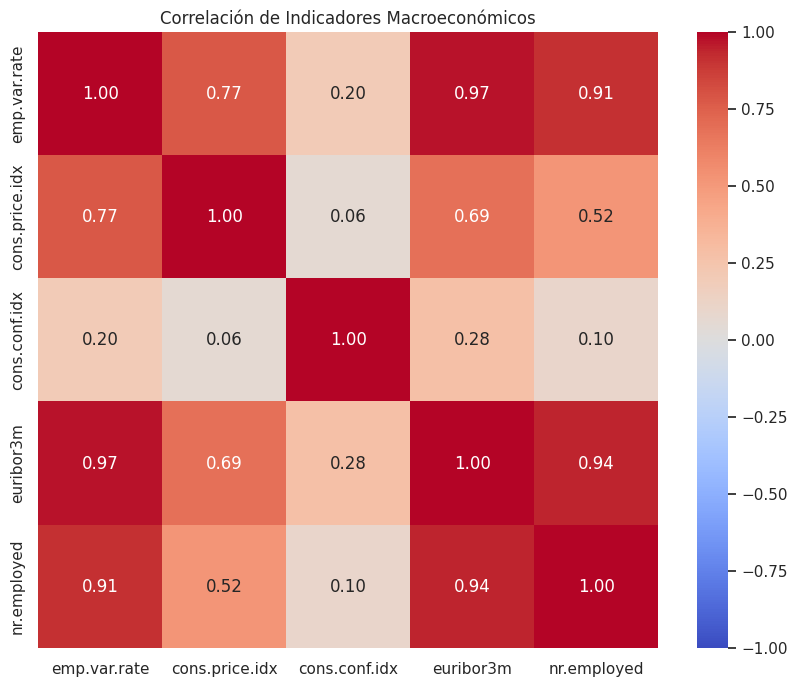

In [62]:
# F1. Escribe el código que muestre un mapa de calor con la matriz de correlación de las variables de la lista macro,
# calculada con ent, con los valores anotados en cada celda.

plt.figure(figsize=(10, 8))
matriz_corr = ent[macro].corr()
sns.heatmap(matriz_corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlación de Indicadores Macroeconómicos")
plt.show()

**Tu observación.** Reporta los pares más correlacionados y la decisión que implican. Escribe tu respuesta aquí y compárala con tu predicción.

Si dos indicadores macroeconomicos presentan correlacion alta, incluir ambos puede introducir redundancia por ello consideraria conservar uno, regularizar el modelo o evaluar su contribucion. No eliminaria variables unicamente por correlacion en si: tambien importa su relacion con el objetivo y que los indicadores varian en el tiempo.

### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.


In [63]:
# F2. Escribe el código que muestre el resumen estadístico (describe) de duration por clase de y.

print(ent.groupby('y')['duration'].describe())

       count        mean         std   min    25%    50%    75%     max
y                                                                      
no   29238.0  221.148198  208.303557   0.0   95.0  164.0  279.0  4918.0
yes   3712.0  549.398976  397.490060  63.0  252.0  448.0  737.0  4199.0


**Tu respuesta.** ¿Incluirías `duration` como característica de un modelo que se usará para decidir a quién llamar? Justifica con la definición de la variable y con lo observado. Escribe tu respuesta aquí.

No incluiria duration. El objetivo es predecir si es rentable contactar o no al usuario antes de incurrir en los costos logisticos de llamarlo; sin embargo, es imposible saber cuanto va a durar la llamada antes de hacerla. Incluirla introduce fuga de informacion, falseando drasticamente el rendimiento predictivo del modelo durante la validación y volviendolo inutil.

**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores económicos varían con el tiempo. ¿Qué implica dividir al azar, como en la parte C, para un modelo que se usará en campañas futuras? Escribe tu respuesta aquí.

Al dividir los datos aleatoriamente se extraen registros de diferentes marcos temporales, lo que causa que el modelo en entrenamiento observe dinamicas o precios económicos de periodos cronologicamente posteriores al momento "simulado" de la prueba, rompiendo la causalidad natural de las predicciones financieras. Es necesario dividir de forma cronologica

## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.

| Hallazgo (con cifra) | Decisión | Se aplica en |
| --- | --- | --- |
| El conjunto tiene 41,188 contactos y 21 columnas; la variable objetivo es `y`. | Definir `y` como objetivo binario y excluirla de las características. | Preprocesamiento |
| No hay necesariamente `NaN`, pero existen valores `unknown` en varias variables categóricas; `default` concentra alrededor de 20.9% de valores desconocidos. | Conservar inicialmente `unknown` como categoría y comparar su comportamiento antes de imputar o eliminar registros. | Preprocesamiento |
| `pdays=999` aparece en aproximadamente 96.3% de los contactos y significa que no hubo contacto previo. | Tratar 999 como codigo especial; crear un indicador de contacto previo o separar el codigo de los dias reales. | Preprocesamiento |
| La clase `yes` representa alrededor de 11.27% y `no` 88.73%; el baseline de predecir siempre `no` ronda 88.7% de exactitud. | Evaluar recall, precision, F1 y matriz de confusion, ademas de exactitud; considerar ponderacion de clases si el modelo lo requiere. | Evaluación / modelos |
| `duration` se conoce solo al terminar la llamada y suele diferir marcadamente entre `yes` y `no`. | Excluir `duration` para decidir a quién llamar, evitando fuga de información. | Preprocesamiento / modelos |
| `campaign` tiene cola derecha y se evaluará su asimetria original frente a raiz cuadrada y `log1p`. | Considerar `log1p` si reduce la asimetria y el modelo es sensible a la escala; no transformar automaticamente para arboles. | Preprocesamiento / modelos |
| Los indicadores macroeconomicos comparten variación temporal y algunos pares presentan correlacion alta. | Revisar colinealidad; en modelos lineales, seleccionar variables o aplicar regularizacion. | Modelos |
| Los valores fuera de los limites de Tukey pueden ser observaciones legitimas, especialmente en conteos y duracion. | No eliminarlos automaticamente; validar su significado y comparar el desempeño con tratamiento robusto. | Preprocesamiento / modelos |
| El conjunto esta ordenado temporalmente, de mayo de 2008 a noviembre de 2010. | Para simular campañas futuras, comparar la division aleatoria con una validacion cronologica. | Evaluacion |

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento? Explica el criterio. Escribe tu respuesta aquí.

Las operaciones de descripción general y validación estructural del dominio se efectuaron con el conjunto total, puesto que no requieren interactuar con la variable y. En cambio, cualquier analisis comparativo donde se relaciona el comportamiento de las clases, se analizan medianas, diagramas de cajas, asimetrias o se calculan estadisticas sobre atributos, se ejecuto estrictamente en la base de entrenamiento. El principio es aislar toda toma de decision empirica que dependa de distribuciones para no conocer anticipadamente la realidad de la prueba.

**Tu respuesta.** Si hubieras explorado también el conjunto de prueba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final? Escribe tu respuesta aquí.

La decision sobre que variables descartar por falta de impacto o los calculos de asimetria para transformaciones de re-expresion se hubieran moldeado tomando en cuenta la distribucion de los registros a futuro. Esto habría propiciado un fenomeno de sobreajuste de preparacion, obteniendo puntajes en la evaluacion final significativamente mas altos que los reales.